0.0 1000.0


/tmp/ipykernel_1965918/1093493849.py:23: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, axs = plt.subplots(1,2, figsize=(12,4))


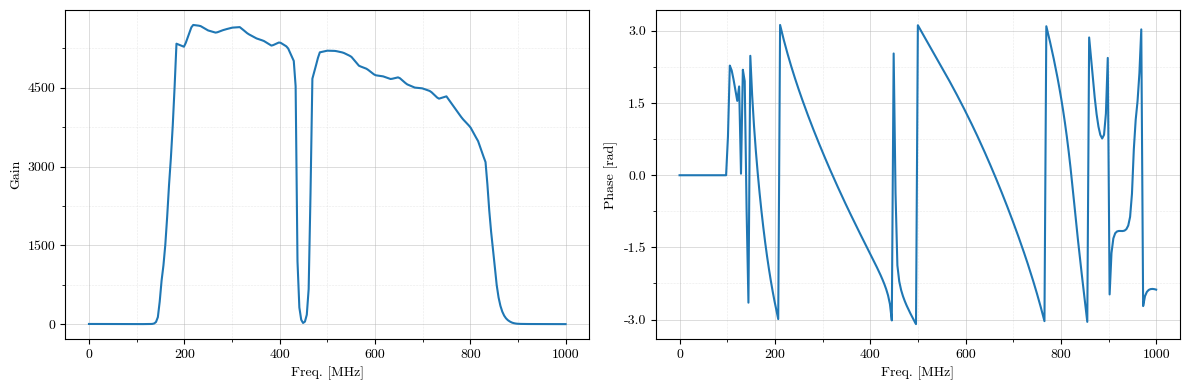

In [20]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from NuRadioReco.utilities import units
matplotlib.use('module://matplotlib_inline.backend_inline')
from matplotlib.ticker import MaxNLocator, AutoMinorLocator
import math

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
})

data = np.loadtxt("/data/condor_shared/users/nmanic/nuradio/myVENV/lib/python3.10/site-packages/NuRadioMC/NuRadioReco/detector/ARA/HardwareResponses/ARA_Electronics_TotalGain_TwoFilters.txt", skiprows=3, delimiter=',')

freq = data[:,0]# MHz
print(freq.min(), freq.max())
gain = data[:,1] # unitless
phase = data[:,2]# rad

fig, axs = plt.subplots(1,2, figsize=(12,4))
axs[0].plot(freq, gain, linewidth=1.5)
axs[1].plot(freq, phase, linewidth=1.5)
axs[0].set_xlabel("Freq. [MHz]")
axs[0].set_ylabel("Gain")
axs[1].set_xlabel("Freq. [MHz]")
axs[1].set_ylabel("Phase [rad]")

for ax in axs:
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.grid(True, which='major', linestyle='-', linewidth=0.6, alpha=.5)
    ax.grid(True, which='minor', linestyle=':', linewidth=0.4, alpha=.5)


plt.tight_layout()
plt.show()

/tmp/ipykernel_1965918/2409775022.py:28: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=figsize)
/tmp/ipykernel_1965918/2409775022.py:45: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=figsize)


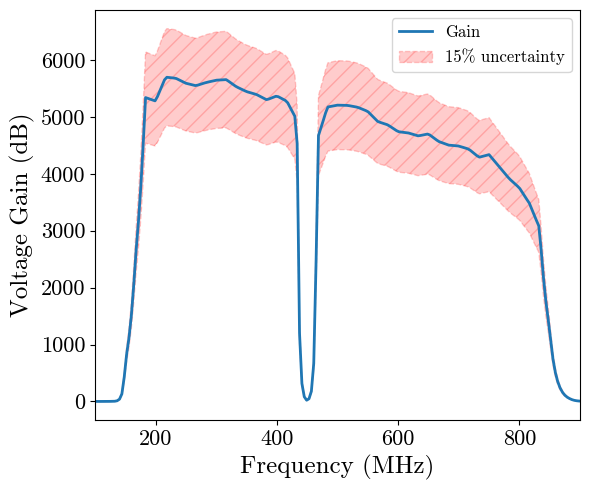

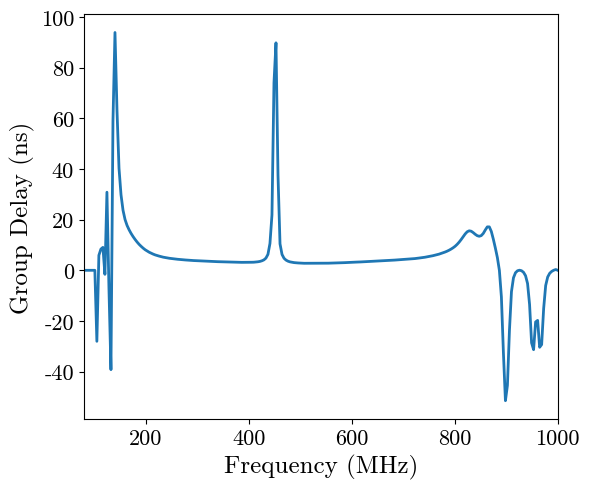

In [26]:
# Code referenced from B. Clark for group delay plotting

freq*=1e6 #convert to Hz for group delay computation
unwrap = np.unwrap(phase)

gdl = np.zeros_like(phase)
max = range(freq.shape[0])
for i in max:
    computed_answer =0
    if (i==0 or i==256):
        computed_answer=0
    else:
        if(unwrap[i+1] ==0 or unwrap[i]==0 or unwrap[i-1]==0):
            computed_answer=0
        else:
            computed_answer = -1* (unwrap[i+1]-unwrap[i-1])/(freq[i+1]-freq[i-1])/(2*math.pi)
    gdl[i]=computed_answer
gdl/=1e-9 #convert to ns for plotting
freq/=1e6 #convert back to MHz for plotting

# impulse=np.array(gain,dtype='complex')
# phases_for_fft = np.cos(phase) + 1j * np.sin(phase)
# impulse *= phases_for_fft
# impulse = np.fft.ifft(impulse).real

labelsize=18
figsize=(6,5)
fig, ax = plt.subplots(figsize=figsize)

ax.plot(freq,gain,linewidth=2,label='Gain')
ax.set_ylabel("Voltage Gain (dB)",fontsize=labelsize)
ax.set_xlabel("Frequency (MHz)",fontsize=labelsize)
ax.set_xlim(100,900)
ax.tick_params(axis='both', which='major', labelsize=16)

plus_sigma=gain*1.15
minus_sigma=gain*.85
# axs[0].plot(freq, plus_sigma, linewidth=2, color='red', ls="--", alpha=.2)
# axs[0].plot(freq, minus_sigma, linewidth=1, color='red', ls="--", alpha=.2)
ax.fill_between(freq, plus_sigma, minus_sigma, facecolor='red', edgecolor='red', hatch='//', ls='--', alpha=.2, label='15% uncertainty')
ax.legend(fontsize=12)

plt.tight_layout()

fig, ax = plt.subplots(figsize=figsize)
ax.plot(freq,gdl,linewidth=2,label='Group Delay')
ax.set_ylabel("Group Delay (ns)",fontsize=labelsize)
ax.set_xlabel("Frequency (MHz)",fontsize=labelsize)
#axs[2].set_ylim([-2,20])
ax.set_xlim(80,1000)
ax.tick_params(axis='both', which='major', labelsize=16)

#ax1.grid(which='both')
# for ax in axs:
#     ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
#     ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
#     ax.xaxis.set_minor_locator(AutoMinorLocator(2))
#     ax.yaxis.set_minor_locator(AutoMinorLocator(2))
#     ax.grid(True, which='major', linestyle='-', linewidth=0.6, alpha=.7)
#     ax.grid(True, which='minor', linestyle=':', linewidth=0.4, alpha=.7)

plt.tight_layout()
plt.show()
#fig.savefig('arasim_gain_and_phase.png',edgecolor='none',bbox_inches="tight") #save the figure

# fig2 = plt.figure(figsize=(11.5,8.5/4))
# ax21 = fig2.add_subplot(1,1,1)
# time = np.arange(0,128,0.5)
# ax21.plot(time,impulse)
# print impulse
# fig2.savefig("impulse_test.png")